In [2]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from math import radians, sin, cos, sqrt, atan2
import time  # Import the time module

# Load the dataset
file_path = '2010_2023_IMD_NASA_Delta.xlsx'
data = pd.read_excel(file_path, engine='openpyxl')

# Step 1: Calculate the Original Delta
data['Original_Delta'] = data['Precipitation (mm)_IMD'] - data['Precipitation (mm)_NASA']

# Earth's radius in kilometers
R = 6371

# Haversine formula function to calculate the distance
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * atan2(sqrt(a), sqrt(1 - a))
    return R * c

# Create a lookup dictionary for anchor points grouped by date
grouped_data = data.groupby('Date')
lookup_dict = {date: group.copy() for date, group in grouped_data}

# List of nearest neighbor counts to use
neighbor_counts = [1, 4, 6, 8, 10]

# Initialize an empty DataFrame to store results for each neighbor count
results_df = pd.DataFrame()

# Track the duration for each method
duration_dict = {}

for n_neighbors in neighbor_counts:
    start_time = time.time()  # Start timing for this method
    
    # Copy the original data to avoid overwriting
    temp_data = data.copy()
    
    # Initialize columns for results
    temp_data[f'Predicted_IMD_Precipitation_{n_neighbors}NN'] = np.nan
    temp_data[f'Error_{n_neighbors}NN'] = np.nan

    for i, row in temp_data.iterrows():
        current_date = row['Date']
        current_lat = row['Latitude']
        current_lon = row['Longitude']
        nasa_precip = row['Precipitation (mm)_NASA']
        
        # Get data for the same date
        same_date_data = lookup_dict.get(current_date, pd.DataFrame()).copy()
        
        if not same_date_data.empty:
            # Filter out the current row to find other anchor points
            same_date_data = same_date_data[(same_date_data['Latitude'] != current_lat) | 
                                            (same_date_data['Longitude'] != current_lon)].copy()
            
            if not same_date_data.empty:
                # Calculate Haversine distance for each row and find the N nearest rows
                same_date_data['Distance'] = same_date_data.apply(
                    lambda x: haversine(current_lat, current_lon, x['Latitude'], x['Longitude']), axis=1)
                
                # Sort by distance and select the N nearest points
                nearest_rows = same_date_data.nsmallest(n_neighbors, 'Distance')
                
                # Calculate the average delta of the N nearest points
                nearest_deltas = nearest_rows['Precipitation (mm)_IMD'] - nearest_rows['Precipitation (mm)_NASA']
                average_delta = nearest_deltas.mean()
                
                # Calculate Predicted IMD Precipitation
                predicted_imd_precip = nasa_precip + average_delta
                temp_data.at[i, f'Predicted_IMD_Precipitation_{n_neighbors}NN'] = predicted_imd_precip
                
                # Calculate Error
                error = row['Precipitation (mm)_IMD'] - predicted_imd_precip
                temp_data.at[i, f'Error_{n_neighbors}NN'] = error

    # Calculate and print error metrics for the current neighbor count
    mse = mean_squared_error(temp_data['Precipitation (mm)_IMD'], temp_data[f'Predicted_IMD_Precipitation_{n_neighbors}NN'], squared=True)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(temp_data['Precipitation (mm)_IMD'], temp_data[f'Predicted_IMD_Precipitation_{n_neighbors}NN'])
    r2 = r2_score(temp_data['Precipitation (mm)_IMD'], temp_data[f'Predicted_IMD_Precipitation_{n_neighbors}NN'])
    
    print(f"\nMetrics for {n_neighbors} Nearest Neighbors:")
    print(f"Mean Squared Error (MSE): {mse}")
    print(f"Root Mean Squared Error (RMSE): {rmse}")
    print(f"Mean Absolute Error (MAE): {mae}")
    print(f"R-squared (R2): {r2}")
    
    # Track the duration taken for this method
    end_time = time.time()
    duration_dict[n_neighbors] = end_time - start_time
    
    # Append the relevant columns to the results DataFrame
    results_df = pd.concat([results_df, temp_data[[f'Predicted_IMD_Precipitation_{n_neighbors}NN', f'Error_{n_neighbors}NN']]], axis=1)

# Concatenate results with the original data and save to file
final_output = pd.concat([data, results_df], axis=1)
output_file = 'bias_function_all_nearest_anchors_with_duration.xlsx'
final_output.to_excel(output_file, index=False)

# Print durations for each method
print("\nDuration for each method (in seconds):")
for n_neighbors, duration in duration_dict.items():
    print(f"{n_neighbors} Nearest Neighbors: {duration:.2f} seconds")

print(f"\nUpdated dataset with all neighbor methods saved to {output_file}")



Metrics for 1 Nearest Neighbors:
Mean Squared Error (MSE): 22.11173713877697
Root Mean Squared Error (RMSE): 4.702311892971049
Mean Absolute Error (MAE): 0.9837007095680177
R-squared (R2): 0.8487487411098641

Metrics for 4 Nearest Neighbors:
Mean Squared Error (MSE): 15.56764713672983
Root Mean Squared Error (RMSE): 3.945585778655665
Mean Absolute Error (MAE): 1.178867714846933
R-squared (R2): 0.893512381564154

Metrics for 6 Nearest Neighbors:
Mean Squared Error (MSE): 19.935625586421956
Root Mean Squared Error (RMSE): 4.464932875914481
Mean Absolute Error (MAE): 1.3885176146990508
R-squared (R2): 0.8636340307509868

Metrics for 8 Nearest Neighbors:
Mean Squared Error (MSE): 19.912376886579786
Root Mean Squared Error (RMSE): 4.462328639463905
Mean Absolute Error (MAE): 1.4081045296600123
R-squared (R2): 0.8637930591935111

Metrics for 10 Nearest Neighbors:
Mean Squared Error (MSE): 21.159013359391633
Root Mean Squared Error (RMSE): 4.599892755205455
Mean Absolute Error (MAE): 1.45717

In [3]:
import pandas as pd

# Dictionary to store the error metrics for each neighbor count
comparison_metrics = {
    'Neighbors': [],
    'MSE': [],
    'RMSE': [],
    'MAE': [],
    'R2': []
}

# Load the dataset with predicted values for each nearest-neighbor method
final_output = pd.read_excel('bias_function_all_nearest_anchors.xlsx', engine='openpyxl')

# List of nearest neighbor counts
neighbor_counts = [1, 4, 6, 8, 10]

# Calculate and store metrics for each neighbor count
for n_neighbors in neighbor_counts:
    predicted_column = f'Predicted_IMD_Precipitation_{n_neighbors}NN'
    
    # Filter out rows with NaN values in the predicted column (if any)
    temp_data = final_output.dropna(subset=[predicted_column])
    
    # Extract actual and predicted values
    y_true = temp_data['Precipitation (mm)_IMD']
    y_pred = temp_data[predicted_column]
    
    # Calculate error metrics
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    # Append results to the dictionary
    comparison_metrics['Neighbors'].append(n_neighbors)
    comparison_metrics['MSE'].append(mse)
    comparison_metrics['RMSE'].append(rmse)
    comparison_metrics['MAE'].append(mae)
    comparison_metrics['R2'].append(r2)
    
    #print(f"\nMetrics for {n_neighbors} Nearest Neighbors:")
    #print(f"Mean Squared Error (MSE): {mse}")
    #print(f"Root Mean Squared Error (RMSE): {rmse}")
    #print(f"Mean Absolute Error (MAE): {mae}")
    #print(f"R-squared (R2): {r2}")

# Convert the dictionary to a DataFrame for easy analysis
comparison_df = pd.DataFrame(comparison_metrics)

# Save the comparison metrics to an Excel file
comparison_output_file = 'nearest_neighbors_comparison_metrics.xlsx'
comparison_df.to_excel(comparison_output_file, index=False)
print(f"\nComparison of error metrics saved to {comparison_output_file}")

# Display the comparison DataFrame
print("\nSummary of Error Metrics for Each Nearest Neighbor Method:")
print(comparison_df)



Comparison of error metrics saved to nearest_neighbors_comparison_metrics.xlsx

Summary of Error Metrics for Each Nearest Neighbor Method:
   Neighbors        MSE      RMSE       MAE        R2
0          1  22.111737  4.702312  0.983701  0.848749
1          4  15.567647  3.945586  1.178868  0.893512
2          6  19.935626  4.464933  1.388518  0.863634
3          8  19.912377  4.462329  1.408105  0.863793
4         10  21.159013  4.599893  1.457176  0.855266


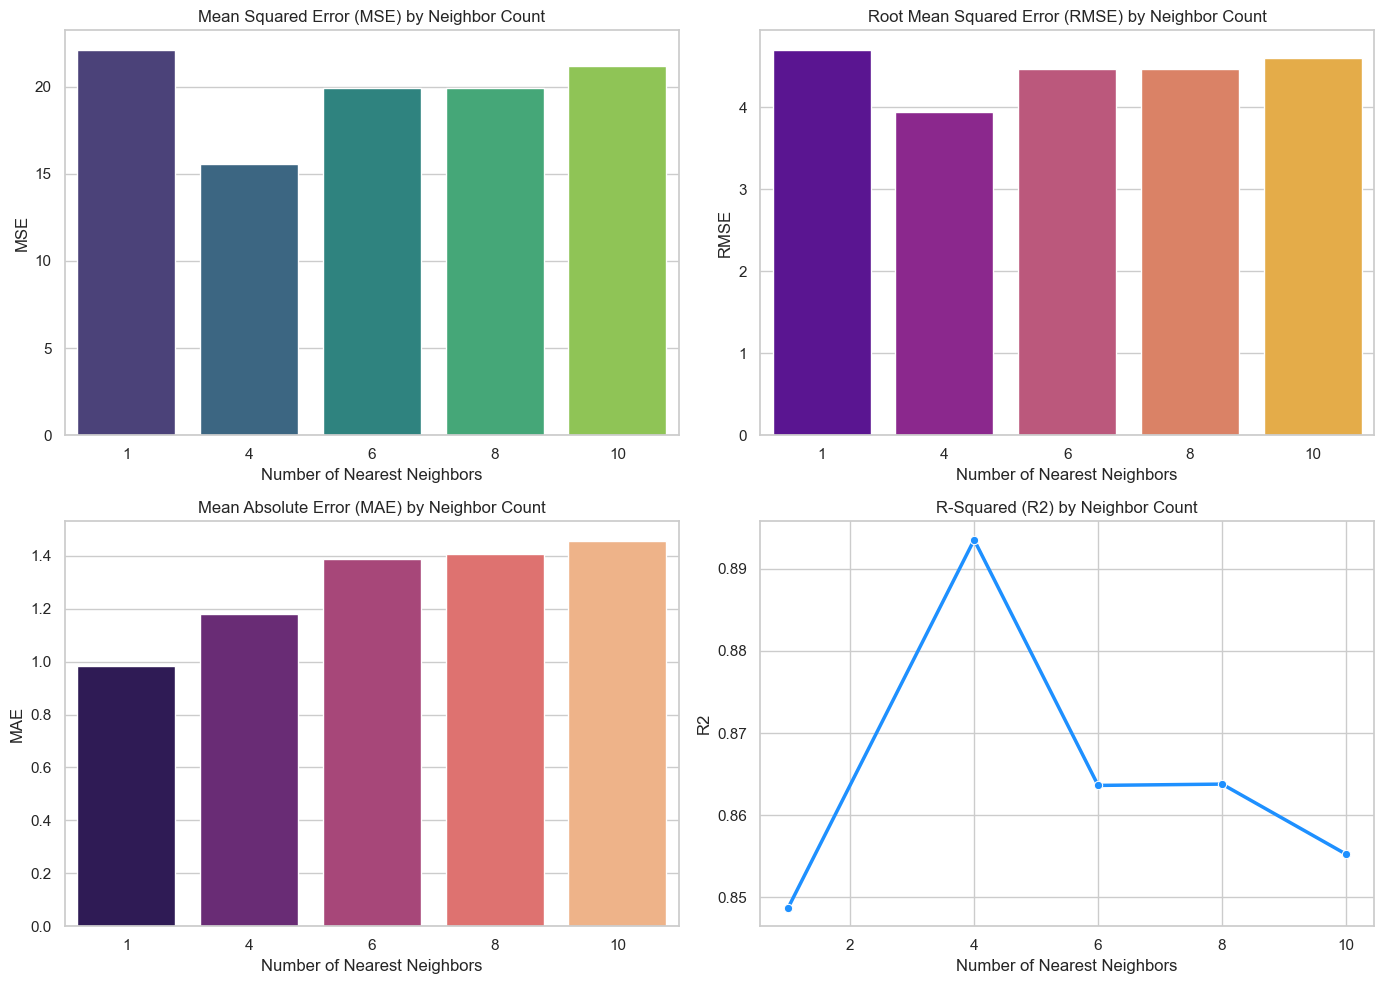

In [4]:
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

# Load the comparison metrics data from the Excel file
comparison_df = pd.read_excel('nearest_neighbors_comparison_metrics.xlsx', engine='openpyxl')

# Set the style for the plots
sns.set(style="whitegrid")

# Create a figure with multiple subplots
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Plot MSE
sns.barplot(data=comparison_df, x='Neighbors', y='MSE', ax=axs[0, 0], palette="viridis")
axs[0, 0].set_title("Mean Squared Error (MSE) by Neighbor Count")
axs[0, 0].set_xlabel("Number of Nearest Neighbors")
axs[0, 0].set_ylabel("MSE")

# Plot RMSE
sns.barplot(data=comparison_df, x='Neighbors', y='RMSE', ax=axs[0, 1], palette="plasma")
axs[0, 1].set_title("Root Mean Squared Error (RMSE) by Neighbor Count")
axs[0, 1].set_xlabel("Number of Nearest Neighbors")
axs[0, 1].set_ylabel("RMSE")

# Plot MAE
sns.barplot(data=comparison_df, x='Neighbors', y='MAE', ax=axs[1, 0], palette="magma")
axs[1, 0].set_title("Mean Absolute Error (MAE) by Neighbor Count")
axs[1, 0].set_xlabel("Number of Nearest Neighbors")
axs[1, 0].set_ylabel("MAE")

# Plot R2
sns.lineplot(data=comparison_df, x='Neighbors', y='R2', marker='o', ax=axs[1, 1], color="dodgerblue", linewidth=2.5)
axs[1, 1].set_title("R-Squared (R2) by Neighbor Count")
axs[1, 1].set_xlabel("Number of Nearest Neighbors")
axs[1, 1].set_ylabel("R2")

# Adjust layout and show the plot
plt.tight_layout()
plt.show()
